In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

scores = pd.read_csv(
    PROJECT_ROOT / "data/results/focal_self_assertion_scores.csv"
)

# Average across the 10 annual speeches per country
country_scores = (
    scores.groupby("iso3", as_index=False)
    .agg(
        mean_sa=("sa_per_1000", "mean"),
        sd_sa=("sa_per_1000", "std")
    )
    .sort_values("mean_sa", ascending=False)
)

display(country_scores)

Matplotlib is building the font cache; this may take a moment.


,iso3,mean_sa,sd_sa
1,CHN,4.440029,1.199231
14,SAU,4.205061,1.243128
2,COL,3.539488,1.262328
17,USA,3.362383,1.274400
9,KAZ,3.210333,1.347368
10,KEN,2.782892,1.100522
12,POL,2.698011,0.972793
16,TJK,2.687776,1.706613
0,CHL,2.659907,1.785706
15,THA,2.484810,1.463199


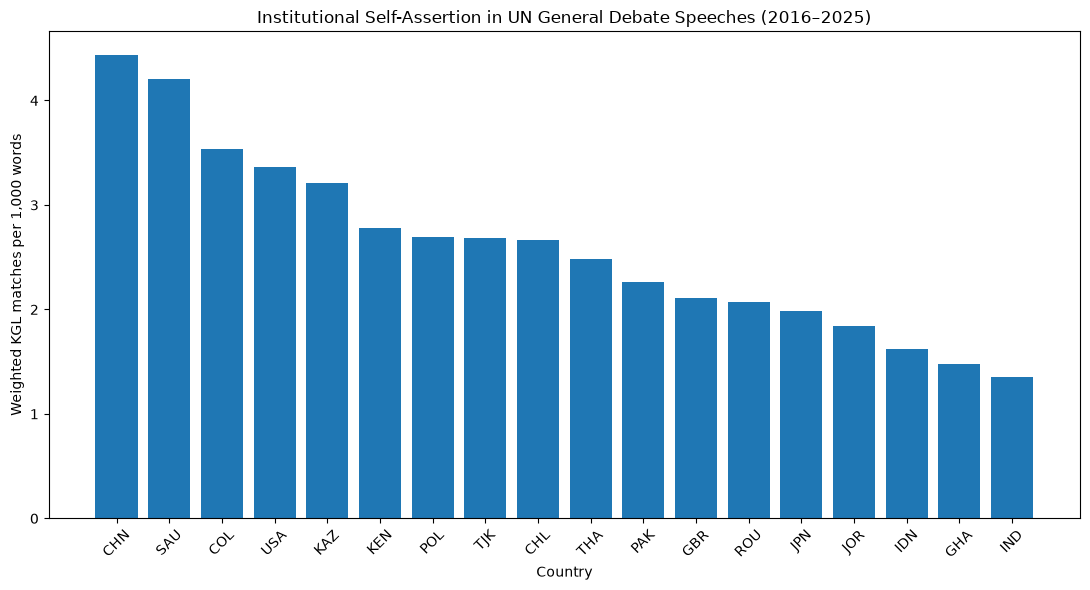

In [2]:
plt.figure(figsize=(11, 6))

plt.bar(
    country_scores["iso3"],
    country_scores["mean_sa"]
)

plt.xlabel("Country")
plt.ylabel("Weighted KGL matches per 1,000 words")
plt.title("Institutional Self-Assertion in UN General Debate Speeches (2016–2025)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()